# KAN-7 — Agregações do histórico de pedidos

Projeto CIN0144 · Tema 8: Praso — Previsão de Inadimplência.

Objetivo: transformar a tabela de pedidos (uma linha por pedido) em uma tabela de **features comportamentais por cliente**, indexada por `id_cliente`, para o modelo comportamental (KAN-8).

**Regras**
- O código fica em `src/features_comportamentais.py`. Tudo lá é determinístico e linha a linha por cliente: nada olha o alvo nem estatísticas do conjunto de clientes, então pode rodar na base inteira.
- **Todo cruzamento com o alvo usa só o treino** do split compartilhado (`src/split.py`, KAN-5). O teste fica intocado para a avaliação final.
- Os dados não têm data de referência, e não sabemos se o último pedido de cada cliente é anterior à inadimplência ou é o próprio evento. A seção 4 formula as duas hipóteses, **(a)** o último pedido é anterior à inadimplência e **(b)** o último pedido é o evento, testa as duas no histórico dos inadimplentes e escolhe **uma versão** das features, a única usada no resto do notebook.

> Os CSVs ficam em `data/raw/` e **não vão para o GitHub** (termo de confidencialidade da Praso). Aqui aparecem só agregados, nunca linhas de clientes.

## 1. Configuração

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline

sys.path.insert(0, str(Path.cwd().parent))
from src import avaliacao as av
from src import dados
from src import features_aplicacao as fa
from src import features_comportamentais as fc
from src import split as sp

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)
FIG = Path("../reports/figures")
AZUL, LARANJA = "#2a78d6", "#eb6834"  # paleta da EDA

In [2]:
clientes, pedidos = dados.carregar_dados_limpos()

# Split da KAN-5: recriado pela seed e conferido com o salvo, se existir
split = sp.criar_split(clientes, pedidos)
if sp.ARQ_SPLIT.exists():
    assert sp.carregar_split().sort_index().equals(split.sort_index()), "split salvo diferente do recriado"
else:
    sp.salvar_split(split)
conjunto = clientes["id_cliente"].map(split)
treino = clientes[conjunto == "treino"].reset_index(drop=True)
alvo_treino = treino.set_index("id_cliente")["inadimplente"]

tem_pedidos = clientes["id_cliente"].isin(pedidos["id_cliente"])
pd.DataFrame({
    "clientes": conjunto.value_counts(),
    "com pedidos": tem_pedidos.groupby(conjunto).sum(),
    "inadimplentes com pedidos": (tem_pedidos & clientes["inadimplente"].eq(1)).groupby(conjunto).sum(),
}).loc[["treino", "teste"]]

,clientes,com pedidos,inadimplentes com pedidos
id_cliente,,,
treino,2400,531,110
teste,600,133,28


**Leitura:** 531 dos 2.400 clientes do treino têm pedidos, e só 110 deles são inadimplentes. No teste são 133 com pedidos e 28 inadimplentes. Todo resultado nos clientes com pedidos tem erro padrão grande, e a seção 7 mede isso fold a fold.

## 2. Conversão das faixas

`fc.converter_pedidos` representa cada faixa pelo **ponto médio** (`_num`) e pela **posição** (`_ord`, código da categórica ordenada da limpeza). Duas exceções:
- a última faixa é aberta (`(2000, 10000000]`, `(60, 10000000]`): vale o limite inferior, porque o teto é artificial;
- atraso `(-100, 0]` significa entregue sem atraso: vale 0 (o ponto médio seria −50).

In [3]:
pc = fc.converter_pedidos(pedidos)
tabelas = []
for col in ["valor", "atraso"]:
    t = pc.groupby(col, observed=True).agg(num=(f"{col}_num", "first"), ord=(f"{col}_ord", "first"), pedidos=(col, "size"))
    t["% dos pedidos"] = t["pedidos"] / t["pedidos"].sum()
    tabelas.append(t.rename_axis("faixa").assign(coluna=col).set_index("coluna", append=True).swaplevel())
pd.concat(tabelas)

num   ord  pedidos  % dos pedidos
coluna faixa                                                  
valor  (0, 500]          250.000 0.000     1577          0.798
       (500, 1000]       750.000 1.000      278          0.141
       (1000, 2000]     1500.000 2.000       97          0.049
       (2000, 10000000] 2000.000 3.000       24          0.012
atraso (-100, 0]           0.000 0.000      543          0.275
       (0, 2]              1.000 1.000      903          0.457
       (2, 4]              3.000 2.000      255          0.129
       (4, 6]              5.000 3.000      105          0.053
       (6, 10]             8.000 4.000       74          0.037
       (10, 15]           12.500 5.000       40          0.020
       (15, 30]           22.500 6.000       28          0.014
       (30, 60]           45.000 7.000       16          0.008
       (60, 10000000]     60.000 8.000       12          0.006

**Leitura:** 80% dos pedidos estão na menor faixa de valor, então o valor varia pouco. No atraso, só 27% foram entregues sem atraso e 46% atrasaram de 1 a 2 dias. A faixa `(0, 2]` é a mais comum, e por isso `pct_atraso` (qualquer atraso) separa menos que `pct_atraso_2d` (acima de 2 dias).

## 3. Estrutura do histórico

Quantos pedidos cada cliente tem, com que ritmo, e o que fazer com os pedidos com nulo e com os pedidos repetidos no mesmo dia. Só contagens, sem o alvo.

In [4]:
por_cliente = pedidos.groupby("id_cliente").size()
ordenados = fc.ordenar_pedidos(pc)
intervalo = ordenados.groupby("id_cliente")["data_entrega"].diff().dt.days.dropna()
pd.Series({
    "pedidos": len(pedidos),
    "clientes com pedidos": por_cliente.size,
    "clientes com 3 / 2 / 1 pedidos": " / ".join(str((por_cliente == k).sum()) for k in [3, 2, 1]),
    "primeira e última data": f"{pedidos['data_entrega'].min():%m/%Y} a {pedidos['data_entrega'].max():%m/%Y}",
    "% dos pedidos em 2023": f"{(pedidos['data_entrega'].dt.year == 2023).mean():.0%}",
    "mediana de dias entre pedidos": intervalo.median(),
    "pares de pedidos no mesmo dia": int((intervalo == 0).sum()),
}, name="valor").to_frame()

,valor
pedidos,1977
clientes com pedidos,664
clientes com 3 / 2 / 1 pedidos,651 / 11 / 2
primeira e última data,04/2022 a 04/2026
% dos pedidos em 2023,77%
mediana de dias entre pedidos,15.000
pares de pedidos no mesmo dia,74


**Leitura:** 651 dos 664 clientes têm **exatamente 3 pedidos**, então isto parece um recorte com os últimos 3 pedidos de cada cliente, não o histórico completo. O volume de compras não é observável: `n_pedidos` fica no dicionário para conferência, mas não entra no modelo. As features úteis descrevem **como** foram esses pedidos (atraso, valor, ritmo). As datas vão de 2022 a 2026, mas 77% dos pedidos são de 2023.

### 3.1 Pedidos com nulo

A limpeza (KAN-1) manteve os 2 pedidos com nulo e deixou a decisão para cá. Em que posição do histórico eles estão?

In [5]:
nulos = dados.pedidos_com_nulo(ordenados)
posicao = ordenados.groupby("id_cliente").cumcount(ascending=False).map({0: "último", 1: "penúltimo", 2: "antepenúltimo"})
pd.DataFrame({
    "sem valor": ordenados.loc[nulos, "valor"].isna().groupby(posicao[nulos]).sum(),
    "sem atraso": ordenados.loc[nulos, "atraso"].isna().groupby(posicao[nulos]).sum(),
}).rename_axis("posição do pedido")

,sem valor,sem atraso
posição do pedido,,
penúltimo,1,1


**Decisão:** os 2 pedidos ficam. Os dois são o penúltimo pedido do cliente, um sem valor e outro sem atraso. A data deles vale, então contam em `n_pedidos`, nos intervalos e no span. Nas estatísticas da coluna que falta, o nulo é ignorado (a média de atraso do cliente sai dos outros 2 pedidos). Se a seção 4.4 escolher a versão (b), sem o último pedido, o pedido sem atraso vira o último do cliente, e `atraso_ultimo` fica nulo para 1 cliente.

### 3.2 Pedidos repetidos no mesmo dia

Há pedidos do mesmo cliente, no mesmo dia e na mesma faixa de valor. Antes de tratá-los como duplicatas, vale ver se isso é mais do que o acaso explicaria, já que ~80% dos pedidos caem na faixa `(0, 500]`.

In [6]:
mesmo_dia = pedidos.duplicated(["id_cliente", "data_entrega"])
mesma_faixa = pedidos.duplicated(["id_cliente", "data_entrega", "valor"])
mesmo_tudo = pedidos.duplicated(["id_cliente", "data_entrega", "valor", "atraso"])
p_faixa = (pedidos["valor"].value_counts(normalize=True) ** 2).sum()  # chance de dois pedidos caírem na mesma faixa
pd.Series({
    "id_pedido repetido": int(pedidos["id_pedido"].duplicated().sum()),
    "pedidos excedentes no mesmo dia": int(mesmo_dia.sum()),
    "... e na mesma faixa de valor": int(mesma_faixa.sum()),
    "... esperado pelo acaso": round(mesmo_dia.sum() * p_faixa, 1),
    "... e também na mesma faixa de atraso": int(mesmo_tudo.sum()),
}, name="pedidos").to_frame()

,pedidos
id_pedido repetido,0.000
pedidos excedentes no mesmo dia,74.000
... e na mesma faixa de valor,54.000
... esperado pelo acaso,48.800
... e também na mesma faixa de atraso,42.000


**Decisão:** manter todos os pedidos. Nenhum `id_pedido` se repete, a coincidência de faixa de valor (54) é a esperada pelo acaso (~49), e 12 dos 54 têm atraso diferente, então não são cópias. Para quem preferir contar dias em vez de pedidos, `n_dias_com_pedido` junta os pedidos do mesmo dia.

## 4. Vazamento temporal: hipóteses (a) e (b)

> **A partir daqui os cruzamentos com o alvo usam só os clientes do treino.**

Os dados não têm data de referência nem a data em que a inadimplência foi observada. Quase todo cliente tem exatamente 3 pedidos, e não sabemos onde o evento da inadimplência fica em relação a eles. Há duas hipóteses:

| | Hipótese | Consequência para as features |
|---|---|---|
| **(a)** | O último pedido é **anterior** à inadimplência. Os 3 pedidos são comportamento observado antes do evento, que aconteceu fora da base. | Agregar **todos os pedidos**. |
| **(b)** | O último pedido **é o evento** da inadimplência, ou a Praso encerrou a relação logo depois de uma piora no histórico. Usar o atraso dele seria olhar a resposta (vazamento). | Agregar **sem o último pedido** (`excluir_ultimo=True`). |

Roteiro: a seção 4.1 mostra por que a dúvida existe, a 4.2 descarta a recência absoluta, a 4.3 testa as duas hipóteses no histórico dos inadimplentes e a 4.4 escolhe **uma** versão, que é a única usada nas seções 5 a 9.

### 4.1 Sinal por posição do pedido

Se o último pedido for o que gerou a inadimplência, o atraso dele deve separar o alvo muito mais do que o dos pedidos anteriores.

In [7]:
ord_treino = ordenados.join(alvo_treino, on="id_cliente", how="inner")
ord_treino["posicao"] = ord_treino.groupby("id_cliente").cumcount(ascending=False).map(
    {0: "último", 1: "penúltimo", 2: "antepenúltimo"})
ord_treino = ord_treino.dropna(subset=["posicao", "atrasou_2d"])
pos = (ord_treino.groupby(["posicao", ord_treino["atrasou_2d"].map({0: "atraso ≤ 2 dias", 1: "atraso > 2 dias"})])
       ["inadimplente"].agg(pedidos="size", taxa="mean").unstack())
pos = pos.loc[["antepenúltimo", "penúltimo", "último"]]
pos

pedidos                            taxa                
atrasou_2d    atraso > 2 dias atraso ≤ 2 dias atraso > 2 dias atraso ≤ 2 dias
posicao                                                                      
antepenúltimo             122             397           0.279           0.166
penúltimo                 147             382           0.327           0.160
último                    144             387           0.403           0.134

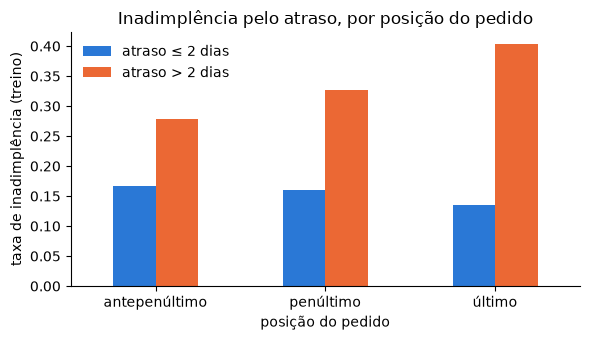

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
pos["taxa"][["atraso ≤ 2 dias", "atraso > 2 dias"]].plot.bar(ax=ax, rot=0, color=[AZUL, LARANJA])
ax.legend(title=None, frameon=False)
ax.set_ylabel("taxa de inadimplência (treino)")
ax.set_xlabel("posição do pedido")
ax.set_title("Inadimplência pelo atraso, por posição do pedido")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "kan7_atraso_por_posicao.png", dpi=150); plt.show()

**Leitura:** quanto mais recente o pedido, mais o atraso separa o alvo. Entre os pedidos com atraso acima de 2 dias, a taxa de inadimplência sobe de 27,9% (antepenúltimo) para 32,7% (penúltimo) e 40,3% (último). Entre os sem atraso relevante, cai de 16,6% para 13,4%. A distância entre os dois grupos passa de 11 para 27 pontos percentuais.

Isso é o que (b) prevê, mas também é o que se espera em (a) se o comportamento recente simplesmente prevê melhor. Esta tabela sozinha não separa as duas hipóteses. A seção 4.3 faz um teste que separa.

### 4.2 Sinal pela época do último pedido

Recência absoluta (dias até uma data fixa) mediria a época em que o cliente comprou. Se a taxa varia muito com a época, a recência capturaria a época, e não o comportamento.

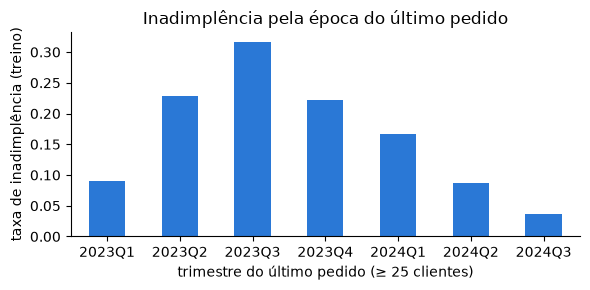

,clientes,taxa
trimestre,,
2023Q1,33,0.091
2023Q2,92,0.228
2023Q3,117,0.316
2023Q4,113,0.221
2024Q1,60,0.167
2024Q2,46,0.087
2024Q3,27,0.037


In [9]:
ultimo = ordenados.groupby("id_cliente")["data_entrega"].max()
epoca = pd.concat([ultimo.dt.to_period("Q").rename("trimestre"), alvo_treino], axis=1, join="inner")
por_epoca = epoca.groupby("trimestre")["inadimplente"].agg(clientes="size", taxa="mean")
por_epoca = por_epoca[por_epoca["clientes"] >= 25]
fig, ax = plt.subplots(figsize=(6, 3))
por_epoca["taxa"].plot.bar(ax=ax, rot=0, color=AZUL)
ax.set_ylabel("taxa de inadimplência (treino)")
ax.set_xlabel("trimestre do último pedido (≥ 25 clientes)")
ax.set_title("Inadimplência pela época do último pedido")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "kan7_taxa_por_epoca.png", dpi=150); plt.show()
por_epoca

**Decisão:** sem recência absoluta. A taxa de inadimplência vai de 3,7% a 31,6% conforme o trimestre do último pedido, e o padrão não é monotônico (sobe até 2023T3 e depois cai). Uma feature de "dias desde o último pedido até uma data fixa" aprenderia a época, que não se repete para clientes novos. A KAN-8 fala em "clientes que compraram nos últimos 30 dias", mas sem uma data de referência esse grupo não tem definição.

### 4.3 Teste das hipóteses: o histórico de quem inadimpliu com o último pedido em dia

As duas hipóteses preveem coisas diferentes para os inadimplentes:

- **Se (b) vale**, o último pedido de um inadimplente mostra o evento e deveria ter atraso alto. Um inadimplente com o último pedido **sem atraso ou com 1 a 2 dias** só é compatível com (b) pela versão do corte: o cliente vinha atrasando muito nos pedidos anteriores e a Praso encerrou a relação. Então esses inadimplentes deveriam ter **atraso grave nos pedidos anteriores**.
- **Se (a) vale**, o evento aconteceu fora dos 3 pedidos. Esses inadimplentes não precisam ter atraso grave antes; no máximo, um histórico um pouco pior que o dos adimplentes.

**Definições** (fixadas antes de ver o resultado):
- último pedido **baixo**: atraso de até 2 dias (faixas `(-100, 0]` e `(0, 2]`), o mesmo limite de `atrasou_2d`;
- atraso **grave**: acima de 15 dias (faixa `(15, 30]` em diante).

**Regra de decisão** (também fixada antes): se **pelo menos metade** dos inadimplentes com o último pedido baixo tiver algum pedido anterior com atraso grave, a hipótese do corte explica esses casos e seguimos **(b)**. Caso contrário, seguimos **(a)**.

A conclusão é generalizada para todos os clientes. Nos inadimplentes com o último pedido acima de 2 dias, (a) e (b) preveem o mesmo atraso alto, então a base não permite testá-los separadamente.

**Passo 1:** quantos inadimplentes têm o último pedido baixo.

In [10]:
ATRASO_BAIXO, ATRASO_GRAVE = 2, 15  # dias; coincidem com limites de faixa (seção 2)

hist = ordenados.join(alvo_treino, on="id_cliente", how="inner")
hist["pos"] = hist.groupby("id_cliente").cumcount(ascending=False)  # 0 = último pedido do cliente
ultimo_ped = hist[hist["pos"] == 0].set_index("id_cliente")
grupo_ultimo = pd.cut(ultimo_ped["atraso_num"], [-np.inf, 0, ATRASO_BAIXO, np.inf],
                      labels=["sem atraso", "1 a 2 dias", "mais de 2 dias"]).rename("atraso do último pedido")

contagem = pd.crosstab(grupo_ultimo, ultimo_ped["inadimplente"].map({0: "adimplentes", 1: "inadimplentes"}))
contagem["taxa"] = contagem["inadimplentes"] / contagem[["adimplentes", "inadimplentes"]].sum(axis=1)
contagem["% dos inadimplentes"] = contagem["inadimplentes"] / contagem["inadimplentes"].sum()
contagem

inadimplente,adimplentes,inadimplentes,taxa,% dos inadimplentes
atraso do último pedido,,,,
sem atraso,142,11,0.072,0.100
1 a 2 dias,193,41,0.175,0.373
mais de 2 dias,86,58,0.403,0.527


**Leitura:** dos 110 inadimplentes do treino com pedidos, **52 (47%) têm o último pedido baixo**: 11 sem atraso (10%) e 41 com 1 a 2 dias (37%). Os outros 58 (53%) têm o último pedido acima de 2 dias.

Se (b) valesse, o último pedido dos inadimplentes deveria mostrar o evento, e quase todos estariam na linha "mais de 2 dias". Quase metade não está. Para esses 52, a única forma de manter (b) é a hipótese do corte, que o passo 2 testa.

A taxa sobe com o atraso do último pedido (7,2% → 17,5% → 40,3%), como já se via na seção 4.1. A faixa de 1 a 2 dias não é neutra: inadimple mais que o dobro da faixa sem atraso.

**Passo 2:** o histórico **anterior** ao último pedido, comparando inadimplentes e adimplentes dentro do mesmo grupo de atraso do último pedido. Para cada cliente:
- `algum anterior > 2 dias`: algum dos pedidos anteriores atrasou mais de 2 dias;
- `penúltimo > 2 dias`: o pedido logo antes do último atrasou mais de 2 dias;
- `algum anterior grave`: algum pedido anterior atrasou mais de 15 dias (é o que a regra usa);
- `pior anterior (mediana)`: mediana, no grupo, do maior atraso entre os pedidos anteriores.

Clientes com um pedido só não têm histórico anterior e ficam de fora.

In [11]:
anteriores = hist[hist["pos"] > 0]
perfil = pd.DataFrame({
    "inadimplente": ultimo_ped["inadimplente"],
    "atraso do último pedido": grupo_ultimo,
    "algum anterior > 2 dias": anteriores.groupby("id_cliente")["atrasou_2d"].max(),
    "penúltimo > 2 dias": anteriores[anteriores["pos"] == 1].set_index("id_cliente")["atrasou_2d"],
    "pior atraso anterior": anteriores.groupby("id_cliente")["atraso_num"].max(),
}).dropna(subset=["pior atraso anterior"])
perfil["algum anterior grave"] = (perfil["pior atraso anterior"] > ATRASO_GRAVE).astype(float)

perfil.groupby(["atraso do último pedido", "inadimplente"], observed=True).agg(**{
    "clientes": ("inadimplente", "size"),
    "algum anterior > 2 dias": ("algum anterior > 2 dias", "mean"),
    "penúltimo > 2 dias": ("penúltimo > 2 dias", "mean"),
    "algum anterior grave": ("algum anterior grave", "mean"),
    "pior anterior (mediana)": ("pior atraso anterior", "median"),
})

clientes  algum anterior > 2 dias  \
atraso do último pedido inadimplente                                      
sem atraso              0                  142                    0.268   
                        1                   11                    0.182   
1 a 2 dias              0                  193                    0.342   
                        1                   40                    0.475   
mais de 2 dias          0                   86                    0.593   
                        1                   58                    0.672   

                                      penúltimo > 2 dias  \
atraso do último pedido inadimplente                       
sem atraso              0                          0.155   
                        1                          0.091   
1 a 2 dias              0                          0.214   
                        1                          0.425   
mais de 2 dias          0                          0.419   
                        1                          0.517   

                                      algum anterior grave  \
atraso do último pedido inadimplente                         
sem atraso              0                            0.035   
                        1                            0.000   
1 a 2 dias              0                            0.016   
                        1                            0.000   
mais de 2 dias          0                            0.081   
                        1                            0.103   

                                      pior anterior (mediana)  
atraso do último pedido inadimplente                           
sem atraso              0                               1.000  
                        1                               1.000  
1 a 2 dias              0                               1.000  
                        1                               1.000  
mais de 2 dias          0                               3.000  
                        1                               3.000

**Leitura:** a tabela tem 51 dos 52 inadimplentes com o último pedido baixo. O que falta tem um pedido só e não tem histórico anterior.

- **Nenhum** dos 51 teve atraso grave (acima de 15 dias) antes do último pedido: 0% nos dois grupos, contra 3,5% e 1,6% dos adimplentes. O pior atraso anterior tem mediana de **1 dia**, igual à dos adimplentes. A hipótese do corte previa o contrário: um histórico de atrasos graves que levasse a Praso a encerrar a relação.
- No grupo **1 a 2 dias**, os inadimplentes têm, sim, um histórico **moderadamente** pior: o penúltimo pedido atrasou mais de 2 dias em 42,5% deles, contra 21,4% dos adimplentes, e algum pedido anterior em 47,5%, contra 34,2%. São atrasos curtos, não uma deterioração grave.
- No grupo **sem atraso**, os 11 inadimplentes têm histórico até mais limpo que os adimplentes (18,2% com algum anterior acima de 2 dias, contra 26,8%). O grupo é pequeno.
- No grupo **mais de 2 dias**, o atraso grave anterior também é raro e parecido entre inadimplentes (10,3%) e adimplentes (8,1%).

Ou seja, o histórico ajuda a prever, como (a) espera, mas não há sinal de corte depois de uma piora grave, que é o que (b) precisaria para explicar esses inadimplentes.

**Passo 3 (sensibilidade):** o limite de 15 dias é uma escolha. A tabela mostra, entre os clientes com o último pedido baixo, a proporção com algum pedido anterior acima de outros limites. A regra continua usando 15 dias; isto só mostra se a conclusão mudaria com outro corte.

In [12]:
baixo = perfil["atraso do último pedido"].isin(["sem atraso", "1 a 2 dias"])
pd.DataFrame({
    f"algum anterior > {d} dias": perfil[baixo].groupby("inadimplente")["pior atraso anterior"].apply(lambda s: (s > d).mean())
    for d in [2, 6, 10, 15, 30]
}).rename(index={0: "adimplentes", 1: "inadimplentes"}).T

inadimplente,adimplentes,inadimplentes
algum anterior > 2 dias,0.310,0.412
algum anterior > 6 dias,0.072,0.118
algum anterior > 10 dias,0.039,0.039
algum anterior > 15 dias,0.024,0.000
algum anterior > 30 dias,0.006,0.000


**Leitura:** a diferença entre inadimplentes e adimplentes com o último pedido baixo só aparece nos atrasos **moderados**: acima de 2 dias (41,2% contra 31,0%) e acima de 6 dias (11,8% contra 7,2%). A partir de 10 dias, os inadimplentes não são piores (3,9% contra 3,9%), e acima de 15 e 30 dias nenhum deles atrasou.

A conclusão não depende do corte de 15 dias. Mesmo com o corte mais frouxo que ainda indica uma piora séria, 6 dias, só 11,8% dos inadimplentes passariam, muito longe da metade que a regra exige.

### 4.4 Decisão: uma versão só

A regra da seção 4.3 aplicada em código. `VERSAO` e `EXCLUIR_ULTIMO` definem as features de todo o resto do notebook.

In [13]:
inad_baixo = perfil[baixo & perfil["inadimplente"].eq(1)]
frac_grave = inad_baixo["algum anterior grave"].mean()
VERSAO = "b" if frac_grave >= 0.5 else "a"
EXCLUIR_ULTIMO = VERSAO == "b"
pd.Series({
    "inadimplentes com o último pedido baixo (com histórico anterior)": len(inad_baixo),
    f"... com algum pedido anterior acima de {ATRASO_GRAVE} dias": int(inad_baixo["algum anterior grave"].sum()),
    "proporção (regra: >= 0,5 -> versão b)": round(frac_grave, 3),
    "versão escolhida": VERSAO,
}, name="valor").to_frame()

,valor
inadimplentes com o último pedido baixo (com histórico anterior),51
... com algum pedido anterior acima de 15 dias,0
"proporção (regra: >= 0,5 -> versão b)",0.000
versão escolhida,a


**Decisão: versão (a), com todos os pedidos.** Nenhum dos 51 inadimplentes com o último pedido baixo e com histórico anterior teve atraso grave antes (proporção 0,000, contra o mínimo de 0,5 da regra). A hipótese do corte não explica esses casos. Para quase metade dos inadimplentes, então, o evento da inadimplência aconteceu **fora** dos pedidos da base, e o último pedido é comportamento anterior a ele. Como definido na seção 4.3, essa conclusão é generalizada para todos os clientes. O sinal mais forte do último pedido na seção 4.1 é lido como o comportamento recente prevendo melhor, coerente com o penúltimo pedido já separar o alvo no passo 2.

A versão (a) também é coerente com o que já se sabia: 802 inadimplentes não têm nenhum pedido na base, e quem atrasou mais de 60 dias inadimple só 22% (EDA, notebook 02). Os dois fatos indicam que a inadimplência é medida fora desta tabela.

**Limitação:** o teste só alcança os inadimplentes com o último pedido baixo. Para os 58 com o último pedido acima de 2 dias, (a) e (b) preveem o mesmo atraso alto, então os dados não distinguem as duas hipóteses nesse grupo. Mas a inadimplência é medida do mesmo jeito para todos os clientes: se, para quase metade dos inadimplentes, o evento está fora dos pedidos da base, não há motivo para supor que, para os demais, ele seja o último pedido. Por isso a regra vale para todos, e a versão (a) é usada para todos os clientes.

## 5. Agregação por cliente e dicionário

`fc.agregar_pedidos` gera uma linha por cliente com pedidos, na versão escolhida na seção 4.4 (`excluir_ultimo=EXCLUIR_ULTIMO`). As features são calculadas na base inteira: cada cliente só depende dos próprios pedidos (a seção 8 confere).

In [14]:
feats = fc.agregar_pedidos(pc, excluir_ultimo=EXCLUIR_ULTIMO)
assert feats.index.is_unique
print(f"versão ({VERSAO}):", feats.shape)
feats.isna().sum().loc[lambda s: s > 0].rename("nulos").to_frame()

versão (a): (664, 17)


,nulos
atraso_tendencia,2
intervalo_medio_dias,2


**Leitura:** a versão (a) tem os 664 clientes com pedidos e 17 colunas (16 features mais `n_pedidos`). Só há nulos em `atraso_tendencia` e `intervalo_medio_dias`, para os 2 clientes com um pedido só, que não têm intervalo nem tendência. Imputar fica com o modelo (KAN-8).

In [15]:
pd.DataFrame.from_dict(fc.DICIONARIO, orient="index", columns=["descrição"]).rename_axis("feature")

,descrição
feature,
n_pedidos,Número de pedidos do cliente (quase sempre 3: ...
n_dias_com_pedido,Número de dias distintos com pedido (vários pe...
valor_media,Média do valor dos pedidos (ponto médio da fai...
valor_mediana,Mediana do valor dos pedidos (ponto médio da f...
valor_min,"Menor valor de pedido (ponto médio da faixa, R$)."
valor_max,"Maior valor de pedido (ponto médio da faixa, R$)."
valor_ord_max,"Maior faixa de valor (0 = (0, 500], 3 = acima ..."
atraso_media,Média do atraso em dias (sem atraso = 0; ponto...
atraso_mediana,Mediana do atraso em dias (sem atraso = 0; pon...


In [16]:
feats.describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
n_pedidos,2.977,0.168,1.000,3.000,3.000
n_dias_com_pedido,2.866,0.358,1.000,3.000,3.000
valor_media,402.359,281.593,250.000,250.000,2000.000
valor_mediana,378.765,309.760,250.000,250.000,2000.000
valor_min,295.181,183.787,250.000,250.000,2000.000
valor_max,533.133,466.884,250.000,250.000,2000.000
valor_ord_max,0.503,0.790,0.000,0.000,3.000
atraso_media,2.711,5.376,0.000,1.000,55.000
atraso_mediana,2.047,5.240,0.000,1.000,60.000
atraso_max,5.081,9.493,0.000,3.000,60.000


## 6. Sinal univariado

AUC de cada feature sozinha contra o alvo, nos clientes do treino com pedidos, na versão escolhida (0,5 = sem sinal; abaixo de 0,5 = relação inversa).

In [17]:
def auc_univariada(f):
    base = f.join(alvo_treino, how="inner")
    return pd.Series({col: roc_auc_score(base.loc[base[col].notna(), "inadimplente"], base.loc[base[col].notna(), col])
                      for col in fc.FEATURES})

auc = auc_univariada(feats).rename(f"AUC ({VERSAO})").sort_values(ascending=False)
print("clientes do treino com pedidos:", feats.index.isin(alvo_treino.index).sum())
auc.to_frame()

clientes do treino com pedidos: 531


,AUC (a)
atraso_ultimo,0.712
atraso_media,0.699
atraso_mediana,0.684
atraso_max,0.684
atraso_ord_max,0.684
pct_atraso_2d,0.678
atraso_tendencia,0.647
pct_atraso,0.620
valor_min,0.473
valor_mediana,0.457


**Leitura:**
- **O sinal está no atraso.** As 8 features de atraso têm AUC de 0,62 a 0,71. As mais fortes são `atraso_ultimo` (0,712) e `atraso_media` (0,699). `pct_atraso` (qualquer atraso, 0,620) é a mais fraca do bloco, porque a faixa de 1 a 2 dias é a mais comum (seção 2).
- **Valor e ritmo têm relação inversa e fraca** (AUC de 0,36 a 0,47): pedidos maiores e intervalos mais longos vêm com um pouco menos de inadimplência. `intervalo_medio_dias` (0,375) e `span_dias` (0,362) podem carregar parte do efeito de época da seção 4.2.
- Pela descrição da seção 5, o valor varia pouco (mediana de R$ 250, a menor faixa) e o atraso típico é de 1 dia. Em média, 73% dos pedidos de um cliente têm algum atraso, mas só 27% passam de 2 dias.

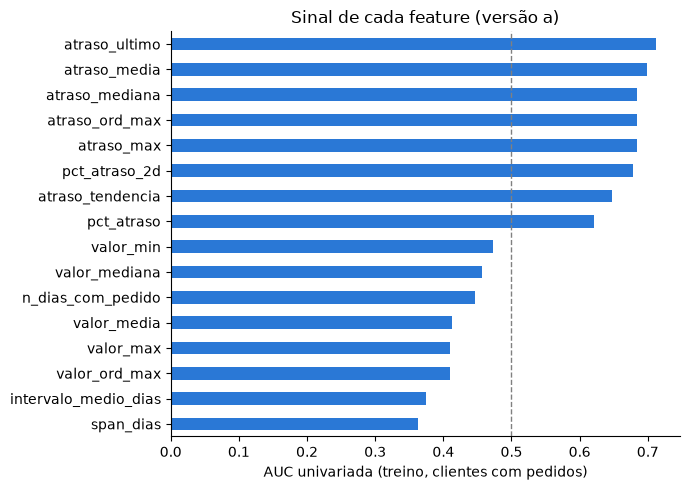

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
auc.sort_values().plot.barh(ax=ax, color=AZUL)
ax.axvline(0.5, color="gray", lw=1, ls="--")
ax.set_xlabel("AUC univariada (treino, clientes com pedidos)")
ax.set_title(f"Sinal de cada feature (versão {VERSAO})")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "kan7_auc_univariada.png", dpi=150); plt.show()

### 6.1 Redundância

Correlação de Spearman entre as features da versão escolhida, nos clientes com pedidos (sem o alvo). Pares muito correlacionados carregam a mesma informação.

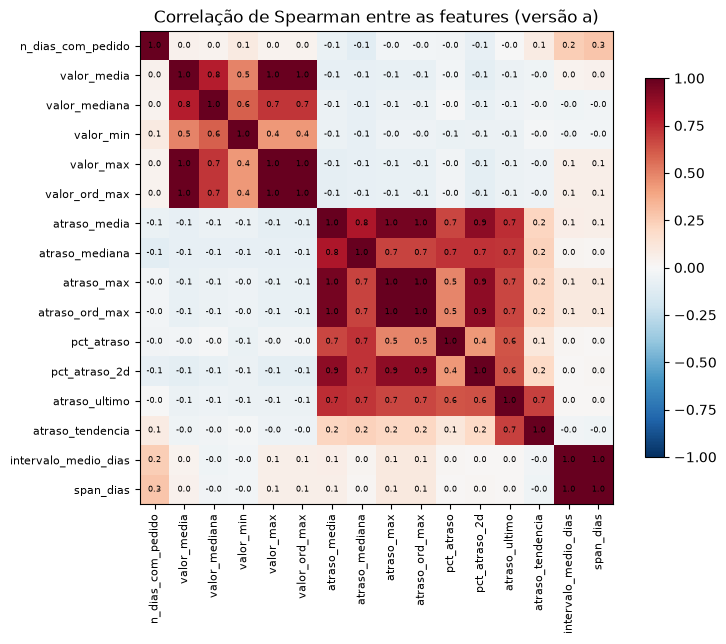

Spearman
valor_max            valor_ord_max      1.000
atraso_max           atraso_ord_max     1.000
intervalo_medio_dias span_dias          0.998
valor_media          valor_ord_max      0.992
                     valor_max          0.992
atraso_media         atraso_max         0.955
                     atraso_ord_max     0.955
atraso_max           pct_atraso_2d      0.893
atraso_ord_max       pct_atraso_2d      0.893
atraso_media         pct_atraso_2d      0.892
                     atraso_mediana     0.805

In [19]:
corr = feats[fc.FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title(f"Correlação de Spearman entre as features (versão {VERSAO})")
plt.tight_layout(); plt.savefig(FIG / "kan7_correlacao.png", dpi=150); plt.show()

triang = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pares = corr.where(triang).stack()
pares[pares.abs() >= 0.8].sort_values(ascending=False).rename("Spearman").to_frame()

**Leitura:** há pares que são a mesma informação: `valor_max` e `valor_ord_max` (1,00), `atraso_max` e `atraso_ord_max` (1,00), `intervalo_medio_dias` e `span_dias` (0,998) e `valor_media` com `valor_max` e `valor_ord_max` (0,99). Com quase todo cliente tendo 3 pedidos, o máximo e a faixa máxima têm a mesma ordem, e o span é 2× o intervalo médio. O bloco de atraso também é muito correlacionado entre si: `atraso_media` com `atraso_max` (0,96) e com `pct_atraso_2d` (0,89), e `atraso_max` com `pct_atraso_2d` (0,89). A KAN-8 pode ficar com um de cada par sem perder nada.

## 7. Quanto os pedidos acrescentam ao modelo de aplicação

A EDA e a seção 6 olham cada feature sozinha. Aqui a pergunta é a da KAN-8: **com as 10 features do modelo de aplicação (KAN-5) já no modelo, os pedidos (na versão escolhida) acrescentam algo?**

- Mesma Random Forest e mesmos 25 folds da KAN-5 (parâmetros fixos, sem tuning; o modelo é da KAN-8).
- O modelo é treinado em todo o treino. Quem não tem pedidos fica com as features comportamentais nulas (a Random Forest do scikit-learn aceita nulos), e "tem pedidos" não entra como feature.
- A avaliação é separada por grupo: o que interessa é o AUC **nos clientes com pedidos** (cerca de 106 por fold de validação, ~22 inadimplentes), então o erro padrão é bem maior que o da KAN-5.
- Blocos: **atraso** (média, mediana, máximo, faixa máxima, % com atraso, % acima de 2 dias, atraso do último e tendência), **valor** e **ritmo** (dias com pedido, intervalo médio, span).

In [20]:
ATRASO = ["atraso_media", "atraso_mediana", "atraso_max", "atraso_ord_max", "pct_atraso", "pct_atraso_2d",
          "atraso_ultimo", "atraso_tendencia"]
VALOR = ["valor_media", "valor_mediana", "valor_min", "valor_max", "valor_ord_max"]
RITMO = ["n_dias_com_pedido", "intervalo_medio_dias", "span_dias"]
assert sorted(ATRASO + VALOR + RITMO) == sorted(fc.FEATURES)

cv = sp.folds(treino, pedidos)
y_treino = treino["inadimplente"]
grupo = treino["id_cliente"].isin(pedidos["id_cliente"]).map({True: "com pedidos", False: "sem pedidos"})
X_apl = fa.criar_features(treino)[fa.FEATURES_FINAIS]
X = pd.concat([X_apl, treino[["id_cliente"]].join(feats, on="id_cliente")[fc.FEATURES]], axis=1)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features="sqrt", n_jobs=-1, random_state=42)


def pipeline(comportamentais):
    """Pré-processador da KAN-5 nas features de aplicação; as comportamentais passam como estão (nulos inclusive)."""
    pre = ColumnTransformer([
        ("aplicacao", fa.montar_preprocessador(fa.FEATURES_FINAIS), fa.FEATURES_FINAIS),
        ("pedidos", "passthrough", comportamentais),
    ], verbose_feature_names_out=False).set_output(transform="pandas")
    return make_pipeline(pre, clone(rf))


configs = {
    "aplicação": [],
    "+ pedidos": fc.FEATURES,
    "+ atraso": ATRASO,
    "+ pedidos sem atraso": VALOR + RITMO,
    "+ pedidos sem atraso_ultimo": [c for c in fc.FEATURES if c != "atraso_ultimo"],
}
por_grupo, inicio = {}, time.time()
for nome, cols in configs.items():
    por_grupo[nome] = av.auc_por_fold_e_grupo(pipeline(cols), X, y_treino, cv, grupo)
    print(f"{nome:<30} {time.time() - inicio:5.0f}s")
print(f"versão das features: ({VERSAO})")
pd.DataFrame({n: g.mean() for n, g in por_grupo.items()}).T[["todos", "com pedidos", "sem pedidos"]]

aplicação                         10s
+ pedidos                         21s
+ atraso                          32s
+ pedidos sem atraso              42s
+ pedidos sem atraso_ultimo       52s
versão das features: (a)


,todos,com pedidos,sem pedidos
aplicação,0.772,0.692,0.788
+ pedidos,0.789,0.787,0.786
+ atraso,0.788,0.776,0.786
+ pedidos sem atraso,0.780,0.717,0.787
+ pedidos sem atraso_ultimo,0.789,0.786,0.785


In [21]:
testes = [
    ("pedidos", "+ pedidos", "aplicação"),
    ("só atraso", "+ atraso", "aplicação"),
    ("valor e ritmo, com o atraso já no modelo", "+ pedidos", "+ atraso"),
    ("atraso, com valor e ritmo já no modelo", "+ pedidos", "+ pedidos sem atraso"),
    ("atraso_ultimo, com o resto já no modelo", "+ pedidos", "+ pedidos sem atraso_ultimo"),
]
pd.DataFrame([
    {"item": item, "avaliado em": g, **av.comparar(por_grupo[com][g], por_grupo[sem][g], cv)}
    for item, com, sem in testes for g in ["com pedidos"]
]).set_index("item")

,avaliado em,ganho,erro padrão,ganho / erro padrão,veredito
item,,,,,
pedidos,com pedidos,0.094,0.030,3.112,acrescenta
só atraso,com pedidos,0.084,0.030,2.794,acrescenta
"valor e ritmo, com o atraso já no modelo",com pedidos,0.011,0.014,0.755,neutro
"atraso, com valor e ritmo já no modelo",com pedidos,0.069,0.032,2.146,acrescenta
"atraso_ultimo, com o resto já no modelo",com pedidos,0.000,0.005,0.085,neutro


**Como ler:** a primeira tabela dá o AUC médio nos 25 folds, em todo o treino e dentro de cada grupo. A segunda dá o ganho pareado **nos clientes com pedidos**, com o erro padrão corrigido e o veredito da regra da KAN-5 (acrescenta se o ganho passa de 1 erro padrão).

**Leitura:**
1. **Os pedidos acrescentam muito para quem tem pedidos.** Nesse grupo, o modelo de aplicação tem AUC 0,692, bem abaixo dos 0,788 de quem não tem pedidos. Com os pedidos, sobe para 0,787: +0,094, 3,1 erros padrão.
2. **O ganho vem do atraso.** Só o bloco de atraso já dá +0,084 (2,8 erros padrão). Com o atraso no modelo, valor e ritmo não acrescentam (+0,011, neutro). Já o atraso acrescenta mesmo com valor e ritmo presentes (+0,069, 2,1 erros padrão).
3. **`atraso_ultimo` é redundante** com o resto do bloco (ganho 0,000): a média, o máximo e as proporções já incluem o último pedido. A KAN-8 pode tirá-la sem perder nada.
4. Para quem não tem pedidos, nada muda (0,788 → 0,786): as features nulas não atrapalham o modelo de aplicação.

> O erro padrão é de 0,005 a 0,032, até cerca de 3× o da KAN-5, porque só ~22 inadimplentes com pedidos entram em cada fold de validação. As conclusões são de direção e ordem de grandeza.

## 8. Checagens de vazamento

Conferências automáticas de que nada do alvo ou do teste entrou nas features, e de que cada cliente só depende dos próprios pedidos. Cada linha é um `assert`.

In [22]:
amostra = pedidos[pedidos["id_cliente"].isin(pedidos["id_cliente"].drop_duplicates().sample(100, random_state=0))]
teste_ids = set(clientes.loc[conjunto == "teste", "id_cliente"])
checagens = {
    "nenhuma feature tem o alvo ou id no nome": not set(fc.DICIONARIO) & {"inadimplente", "id_cliente", "id_pedido"},
    "agregar é por cliente: subconjunto dá o mesmo resultado":
        fc.agregar_pedidos(fc.converter_pedidos(amostra), excluir_ultimo=EXCLUIR_ULTIMO)
          .equals(feats.loc[feats.index.intersection(sorted(amostra["id_cliente"].unique()))]),
    "o alvo do teste não foi lido (seções 4 a 7 usam alvo_treino ou y_treino)":
        not teste_ids & set(alvo_treino.index) and not teste_ids & set(treino["id_cliente"]),
    "juntar_clientes mantém a ordem e as 3.000 linhas":
        fc.juntar_clientes(clientes, feats)["id_cliente"].equals(clientes["id_cliente"]),
}
if EXCLUIR_ULTIMO:
    checagens["(b) não usa o pedido mais recente de ninguém"] = (
        not set(ordenados.groupby("id_cliente")["id_pedido"].last()) & set(fc.remover_ultimo_pedido(pc)["id_pedido"]))
for nome, ok in checagens.items():
    assert ok, nome
pd.Series(checagens, name="ok").to_frame()

,ok
nenhuma feature tem o alvo ou id no nome,True
agregar é por cliente: subconjunto dá o mesmo resultado,True
o alvo do teste não foi lido (seções 4 a 7 usam alvo_treino ou y_treino),True
juntar_clientes mantém a ordem e as 3.000 linhas,True


## 9. Salvar

A versão escolhida na seção 4.4 vai para `data/processed/features_comportamentais.csv` (fora do git). Na KAN-8, o caminho recomendado é recalcular pelo módulo, que é rápido e não perde tipos:

```python
feats = fc.agregar_pedidos(fc.converter_pedidos(pedidos), excluir_ultimo=...)  # conforme a seção 4.4
base = fc.juntar_clientes(clientes, feats)  # left join + tem_pedidos
```

In [23]:
feats.to_csv(dados.DIR_PROCESSED / "features_comportamentais.csv")
base = fc.juntar_clientes(clientes, feats)
print(f"salvo em data/processed/ (versão {VERSAO}) | base juntada:", base.shape, "| tem_pedidos:", int(base["tem_pedidos"].sum()))

salvo em data/processed/ (versão a) | base juntada: (3000, 37) | tem_pedidos: 664


## 10. Resumo

**Entrega**
- `src/features_comportamentais.py`: `converter_pedidos` → `agregar_pedidos` (16 features + `n_pedidos`, em `fc.DICIONARIO`) → `juntar_clientes` (left join com os clientes, mais `tem_pedidos`).
- Versão **(a)**, com todos os pedidos, escolhida na seção 4.4 e salva em `data/processed/features_comportamentais.csv`.
- Tudo é determinístico e por cliente (seção 8): pode rodar na base inteira antes do split.

**Decisões**
- Faixa → ponto médio; faixa aberta → limite inferior; "(-100, 0]" → 0 dias de atraso.
- Os 2 pedidos com nulo e os pedidos repetidos no mesmo dia ficam (seções 3.1 e 3.2).
- `n_pedidos` não entra no modelo (quase todo cliente tem 3). Sem recência absoluta (seção 4.2).
- **Versão (a).** Hipóteses: (a) o último pedido é anterior à inadimplência; (b) o último pedido é o evento. 52 dos 110 inadimplentes do treino com pedidos (47%) têm o último pedido com atraso de até 2 dias, e nenhum dos 51 com histórico anterior teve atraso acima de 15 dias antes dele. A hipótese do corte, a única que salvaria (b) para esses clientes, não se sustenta (seções 4.3 e 4.4).

**Achados**
- O sinal está no **atraso**. Com as features de aplicação no modelo, os pedidos sobem o AUC dos clientes com pedidos de 0,692 para 0,787 (+0,094, 3,1 erros padrão). Só o bloco de atraso dá +0,084, e valor e ritmo não acrescentam com ele presente.
- `atraso_ultimo` é redundante com o resto do bloco de atraso (ganho 0,000).
- Entre os inadimplentes com o último pedido baixo, o histórico é só moderadamente pior que o dos adimplentes (penúltimo acima de 2 dias: 42,5% contra 21,4% no grupo de 1 a 2 dias). Não há atrasos graves.

**Recomendações para a KAN-8**
1. Usar a versão (a) (`excluir_ultimo=False`) e citar no relatório o teste da seção 4.3 como justificativa, com a limitação da seção 4.4.
2. Começar pelo bloco de atraso e, dos pares redundantes da seção 6.1, ficar com um de cada. `atraso_ultimo` pode sair.
3. Usar o mesmo split e os mesmos folds (`sp.carregar_split()`, `sp.folds(treino, pedidos)`), passando os pedidos limpos completos.
4. No teste, só 28 inadimplentes têm pedidos: o AUC nesse grupo terá erro padrão perto de 0,05.